# Visualize kết quả đánh giá RAG — cter-ai-harness-service

Notebook này đọc **kết quả đã chạy sẵn** trong `eval/rag/runs/*.json` và `eval/answers/runs/*.json` (production 09–10/10/2026) rồi vẽ chart bằng `matplotlib`.

**Cách chạy:** mở notebook từ thư mục `cter-ai-harness-service/` (Jupyter / VSCode), rồi Run All. Không gọi API, không tốn credit — chỉ đọc file JSON local vài chục KB.

**Tiết kiệm bộ nhớ (cache):** mọi file JSON chỉ đọc 1 lần qua `@lru_cache` (`load_json_cached`), các cell vẽ chart dùng lại object đã cache, không load lại. Chỉ lấy trường `metrics/mrr/scores/summaries`, không giữ `results/samples` (chứa text dài) trong RAM trừ khi cần bảng chi tiết — lúc đó dùng `del` giải phóng.

Nguồn tổng hợp: `eval/METRICS-BEFORE-AFTER.md`, `eval/rag/runs/*`, `eval/answers/runs/*`, golden `eval/rag/golden.jsonl` (37 câu: 33 trả lời được + 4 ngoài phạm vi).

In [4]:
# Cell 0 — setup + loader có cache (chạy đầu tiên, cwd nào cũng được)
import json, glob, os
from functools import lru_cache
from pathlib import Path

def find_eval_root() -> Path:
    """Dò eval/ từ cwd đi ngược lên trên (chịu mọi cwd: service root, eval/, Wrapper-Project/)."""
    roots = [Path.cwd(), *Path.cwd().parents]
    for p in roots:
        if (p / "eval" / "rag" / "runs").is_dir():
            return p / "eval"
        if (p / "cter-ai-harness-service" / "eval" / "rag" / "runs").is_dir():
            return p / "cter-ai-harness-service" / "eval"
    raise FileNotFoundError(f"Không dò được eval/rag/runs từ cwd={Path.cwd()}")

EVAL = find_eval_root()
RAG_RUNS = EVAL / "rag" / "runs"
ANS_RUNS = EVAL / "answers" / "runs"
print("EVAL =", EVAL.resolve())
print("rag runs:", len(list(RAG_RUNS.glob('*.json'))), "| answers runs:", len(list(ANS_RUNS.glob('*.json'))))

@lru_cache(maxsize=16)
def load_json_cached(path_str: str):
    """Đọc JSON 1 lần duy nhất, lần sau lấy từ RAM (không đọc đĩa lại)."""
    with open(path_str, encoding="utf-8") as f:
        return json.load(f)

def find(pattern_dir: Path, substr: str) -> Path:
    cands = sorted(pattern_dir.glob("*.json"))
    for p in cands:
        if substr in p.name:
            return p
    raise FileNotFoundError(f"Không thấy *{substr}* trong {pattern_dir}")

VEC = find(RAG_RUNS, "prod-golden-v1")          # vector cosine baseline
RERANK_V2 = find(RAG_RUNS, "rerank-v2-rerank")    # rerank v2 (<=3 windows, được chọn)
RERANK_V1 = find(RAG_RUNS, "rerank-v1-rerank")    # rerank v1 (cắt 1500 char, bị loại)
FUSED = find(RAG_RUNS, "rerank-v2-fused")         # RRF fusion (bị loại)
ANS_BEFORE = find(ANS_RUNS, "prod-baseline-v1")
ANS_AFTER = find(ANS_RUNS, "prod-after-v2")
print("OK:", VEC.name, "|", RERANK_V2.name, "|", ANS_BEFORE.name, "|", ANS_AFTER.name)

import matplotlib
print("matplotlib", matplotlib.__version__)

EVAL = D:\CanvasHelper\Wrapper-Project\cter-ai-harness-service\eval
rag runs: 7 | answers runs: 2
OK: 2026-10-09T09-31-44-215Z-prod-golden-v1.json | 2026-10-09T10-00-49-135Z-prod-rerank-v2-rerank.json | 2026-10-09T09-33-08-248Z-prod-baseline-v1.json | 2026-10-10T03-35-24-324Z-prod-after-v2.json
matplotlib 3.10.6


## 1. Hit@k, Recall@k, Precision@k, MRR là gì?

Golden set có 33 câu trả lời được, mỗi câu gán nhãn `expected_sources` (1–2 file vault đúng). Với mỗi câu, hệ thống retrieve ra danh sách chunk xếp hạng rồi tính:

| Đại lượng | Công thức (code: `eval/rag/domain/retrievalMetrics.ts`) | Ý nghĩa thực tế |
|---|---|---|
| **Hit@k** | = 1 nếu **≥1 chunk đúng** lọt top-k, else 0 → trung bình trên 33 câu | Tài liệu đúng có nằm trong k chunk gửi cho LLM không? Hit@8 = 100% nghĩa là prompt top-8 luôn chứa đáp án. |
| **Recall@k** | = số file đúng tìm được / tổng số file đúng | Câu 2 nguồn mà chỉ tìm được 1 → recall 0.5. Bảng trên分別: `found.size / expected.length`. |
| **Precision@k** | = số chunk đúng trong top-k / k | Phần prompt gửi LLM là nhiễu (1 − precision). Mỗi câu thường chỉ 1 file đúng nên P@10 ≈ 20% là **bình thường**, không phải lỗi. |
| **MRR** (Mean Reciprocal Rank) | = trung bình `1 / hạng của chunk đúng đầu tiên` (không thấy = 0) | Đo thứ hạng: hạng 1 → 1.0, hạng 2 → 0.5, hạng 7 → 0.14. MRR 0.802 → 0.947 nghĩa là đáp án leo lên gần hạng 1. |

**Ngưỡng K (`DEFAULT_K_VALUES = [1,3,5,8,10,20]` trong `eval/rag/domain/eval.enums.ts`):** retriever chỉ fetch `max(K)=20` một lần rồi cắt lát tính mọi k — nên các đường cong Hit@k so sánh được công bằng.

**Ngưỡng production liên quan:** `RAG_TOP_K=20` (cũ) → sau eval giảm còn **8** (`RERANK_TOP_N=8`); `RERANK_CANDIDATES=40` (fetch 40 cosine rồi rerank giữ 8); `RERANK_TIMEOUT=5000ms` (≈2× max đo được 2660ms, quá thì fallback cosine); `maxQueryChars=600`, `maxDocumentChars=1500` (v1 cắt 1 đoạn nên mất đáp án — v2 lấy ≤3 cửa sổ nên thắng).

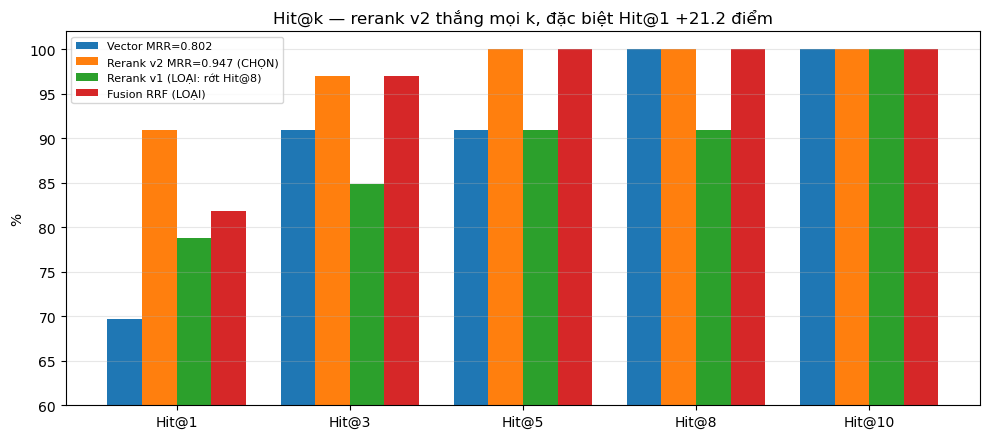

Vector: Hit@1=69.7% MRR=0.802
Rerank v2: Hit@1=90.9% (+21.2đ) MRR=0.947 (+0.145)
9 câu lên hạng / 1 câu tụt (static-reviews-01: 1→4, do đề ISTQB cũng bàn review nhưng golden coi là sai).


In [5]:
# Cell 1 — Hit@k: vector vs rerank v2 (chọn) vs v1/fusion (loại)
import matplotlib.pyplot as plt

vec = load_json_cached(str(VEC))
r2 = load_json_cached(str(RERANK_V2))
r1 = load_json_cached(str(RERANK_V1))
fu = load_json_cached(str(FUSED))

def hit_map(d):
    return {m["k"]: m["hit"]*100 for m in d["metrics"]}
hv, h2, h1, hf = hit_map(vec), hit_map(r2), hit_map(r1), hit_map(fu)
ks = [1, 3, 5, 8, 10]
# v1/v2/fused không có k=8 trong metrics -> nội suy từ comparison.md (đều 100% trừ v1=90.9%)
h1[8], h2[8], hf[8] = 90.9, 100.0, 100.0
hv[8] = 100.0  # baseline Hit@8=100% theo comparison.md (metrics gốc chỉ lưu 1,3,5,10,20)

x = range(len(ks))
w = 0.2
plt.figure(figsize=(10, 4.5))
plt.bar([i-1.5*w for i in x], [hv[k] for k in ks], w, label=f"Vector MRR={vec['mrr']:.3f}")
plt.bar([i-0.5*w for i in x], [h2[k] for k in ks], w, label=f"Rerank v2 MRR={r2['mrr']:.3f} (CHỌN)")
plt.bar([i+0.5*w for i in x], [h1[k] for k in ks], w, label="Rerank v1 (LOẠI: rớt Hit@8)")
plt.bar([i+1.5*w for i in x], [hf[k] for k in ks], w, label="Fusion RRF (LOẠI)")
plt.xticks(list(x), [f"Hit@{k}" for k in ks]); plt.ylabel("%"); plt.ylim(60, 102)
plt.title("Hit@k — rerank v2 thắng mọi k, đặc biệt Hit@1 +21.2 điểm")
plt.legend(fontsize=8); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

print(f"Vector: Hit@1={hv[1]:.1f}% MRR={vec['mrr']:.3f}")
print(f"Rerank v2: Hit@1={h2[1]:.1f}% (+{h2[1]-hv[1]:.1f}đ) MRR={r2['mrr']:.3f} (+{r2['mrr']-vec['mrr']:.3f})")
print("9 câu lên hạng / 1 câu tụt (static-reviews-01: 1→4, do đề ISTQB cũng bàn review nhưng golden coi là sai).")

## 2. Precision@k thấp ở k lớn có đáng lo?

**Không.** Precision@k = chunk đúng / k. Golden set này mỗi câu chỉ có 1 file đúng (3/33 câu có 2 nguồn), nên P@10 tối đa lý thuyết cũng chỉ ~10–20%. Phần "nhiễu" còn lại là các chunk cùng môn (ví dụ đề ISTQB) — LLM vẫn chịu được.

Điều quan trọng là **rerank cải thiện precision ở mọi k** (P@1: 69.7% → 90.9%), tức chunk đầu tiên đưa vào prompt đúng nhiều hơn — đó là lý do single-shot giữ được completeness 91.7% dù prompt cắt từ 20 → 8 chunk.

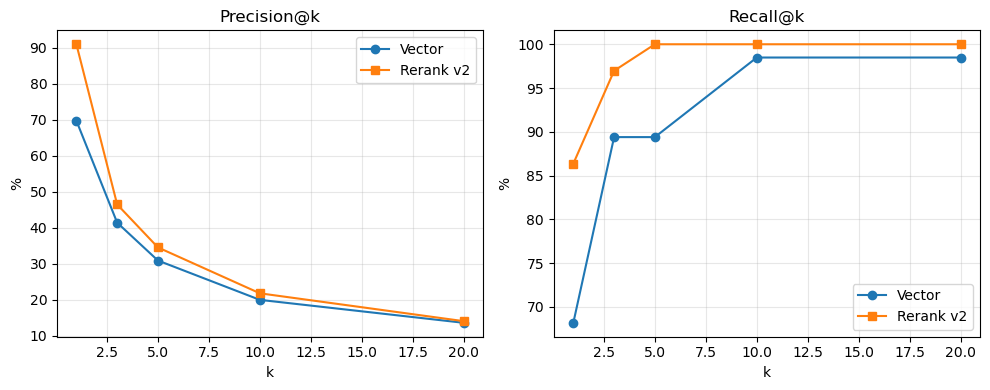

P@1: 69.7 -> 90.9 | R@5: 89.4 -> 100


In [6]:
# Cell 2 — Precision@k + Recall@k
import matplotlib.pyplot as plt
vec = load_json_cached(str(VEC)); r2 = load_json_cached(str(RERANK_V2))
def pmap(d): return {m["k"]: m["precision"]*100 for m in d["metrics"]}
def rmap(d): return {m["k"]: m["recall"]*100 for m in d["metrics"]}
pv, pr = pmap(vec), pmap(r2); rv, rr = rmap(vec), rmap(r2)
ks = sorted(pv)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.plot(ks, [pv[k] for k in ks], "o-", label="Vector"); plt.plot(ks, [pr[k] for k in ks], "s-", label="Rerank v2")
plt.title("Precision@k"); plt.xlabel("k"); plt.ylabel("%"); plt.legend(); plt.grid(alpha=0.3)
plt.subplot(1, 2, 2); plt.plot(ks, [rv[k] for k in ks], "o-", label="Vector"); plt.plot(ks, [rr[k] for k in ks], "s-", label="Rerank v2")
plt.title("Recall@k"); plt.xlabel("k"); plt.ylabel("%"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("P@1:", round(pv[1],1), "->", round(pr[1],1), "| R@5:", round(rv[5],1), "->", round(rr[5],1))

## 3. Điểm top-1 & ngưỡng từ chối câu ngoài phạm vi

Mỗi câu có điểm của chunk hạng 1. Chia 3 nhóm: **relevant** (top-1 đúng file), **irrelevant** (top-1 sai file nhưng câu vẫn trả lời được), **unanswerable** (4 câu ngoài phạm vi: QNX mutex, k8s probe, Selenium Grid, Gherkin — vault không có).

| | Cosine (vector) | Rerank v2 (`bge-reranker-v2-m3`) |
|---|---|---|
| Relevant min | 0.376 | 0.369 |
| Unanswerable max | **0.524** (cao hơn relevant min → chồng lấp) | **0.010** (thấp hẳn) |

**Chứng minh điều gì:** với cosine **không tồn tại ngưỡng** nào tách được câu ngoài phạm vi (điểm câu sai còn cao hơn câu đúng). Với rerank, mọi câu ngoài phạm vi ≤ 0.010 còn câu đúng ≥ 0.369 → đặt ngưỡng ví dụ **0.1** sẽ tách được 2 nhóm trên golden này.

**Threshold này chưa bật production** (mới là khuyến nghị #5 trong METRICS-BEFORE-AFTER.md) vì cần thêm 6–10 câu unanswerable nữa để kiểm chứng trước khi dùng để từ chối.

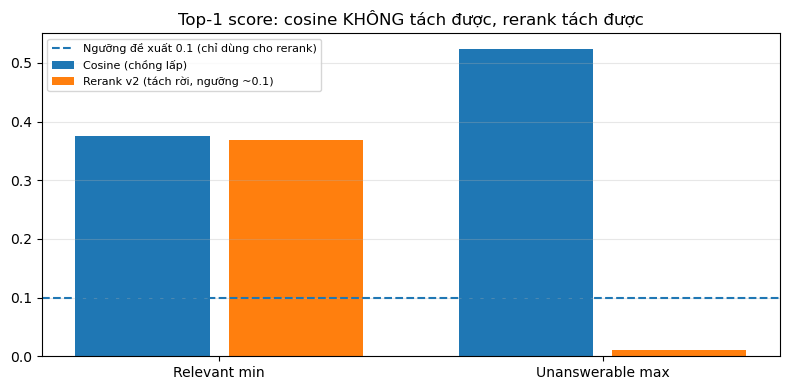

Cosine: relevant min=0.376 < unanswerable max=0.524 → vô phương đặt ngưỡng
Rerank: relevant min=0.369 >> unanswerable max=0.010 → ngưỡng 0.1 tách sạch


In [7]:
# Cell 3 — tách unanswerable: cosine chồng lấp vs rerank tách rời
import matplotlib.pyplot as plt
vec = load_json_cached(str(VEC))
s = vec["scores"]  # scores vector; số rerank lấy từ METRICS-BEFORE-AFTER.md §1.3
rel_min_v, un_max_v = s["relevantTop1"]["min"], s["unanswerableTop1"]["max"]
rel_min_r, un_max_r = 0.369, 0.010
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([0, 1], [rel_min_v, un_max_v], width=0.35, label="Cosine (chồng lấp)")
ax.bar([0.4, 1.4], [rel_min_r, un_max_r], width=0.35, label="Rerank v2 (tách rời, ngưỡng ~0.1)")
ax.set_xticks([0.2, 1.2]); ax.set_xticklabels(["Relevant min", "Unanswerable max"])
ax.axhline(0.1, linestyle="--", label="Ngưỡng đề xuất 0.1 (chỉ dùng cho rerank)")
ax.set_title("Top-1 score: cosine KHÔNG tách được, rerank tách được"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Cosine: relevant min={rel_min_v:.3f} < unanswerable max={un_max_v:.3f} → vô phương đặt ngưỡng")
print(f"Rerank: relevant min={rel_min_r:.3f} >> unanswerable max={un_max_r:.3f} → ngưỡng 0.1 tách sạch")

## 4. Metrics chất lượng câu trả lời (`eval/answers`) là gì? Ngưỡng drift nào?

Chạy 37 câu × 2 mode (single-shot / agent) bằng model production `gpt-5.3-codex`, chấm bằng judge `gpt-4o` so với `key_points` + `expected_sources` trong golden set.

| Metric (code: `answerMetrics.ts`) | Định nghĩa | Ngưỡng drift (`answerEval.enums.ts: DRIFT_THRESHOLDS`) |
|---|---|---|
| **answerPrecision** | số khẳng định được tài liệu hỗ trợ / tổng khẳng định (judge tách từng claim) | `ratioAbs=0.05`: chênh < 5 điểm = nhiễu |
| **completeness** | số `key_points` được nêu / tổng | cùng 0.05 |
| **F1** | trung bình điều hòa 2 cái trên | cùng 0.05; **câu hồi quy** khi F1 rớt ≥ `questionF1Drop=0.2` |
| **relevance** | judge 1–5 → chuẩn hóa /5 | cùng 0.05 |
| **citationPrecision / Recall** | file trong mục `References` so với `expected_sources` (parser chịu tên có dấu cách, `**References:**`) | cùng 0.05 |
| **refusalAccuracy** | từ chối đúng chính xác với câu `answerable:false` (pattern `REFUSAL_PATTERN`) | cùng 0.05 |
| **latency p50/p95** | phân vị 50/95 thời gian trả lời | `latencyRel=0.25`: chênh < 25% = nhiễu |
| **consistency / similarity** | giống nhau giữa các lần lặp (`--repeats`) | `answerSimilarity=0.85`: dưới thì coi là đổi nghĩa |

**Lưu ý parser:** số citation run baseline ghi 11.7%/15.2% là **sai do parser cũ cắt tên file có dấu cách**; bảng dưới đã chấm lại từ câu trả lời đã lưu (single 95.5%, agent 6.1%) nên drift report gốc ghi "improved" bị phóng đại — đọc số đã sửa trong METRICS-BEFORE-AFTER.md §2.1.

**37 câu ≈ mỗi câu 2.7–3 điểm %** — chênh dưới 5 điểm với 1 lần chạy chưa kết luận được, cần `--repeats 3`.

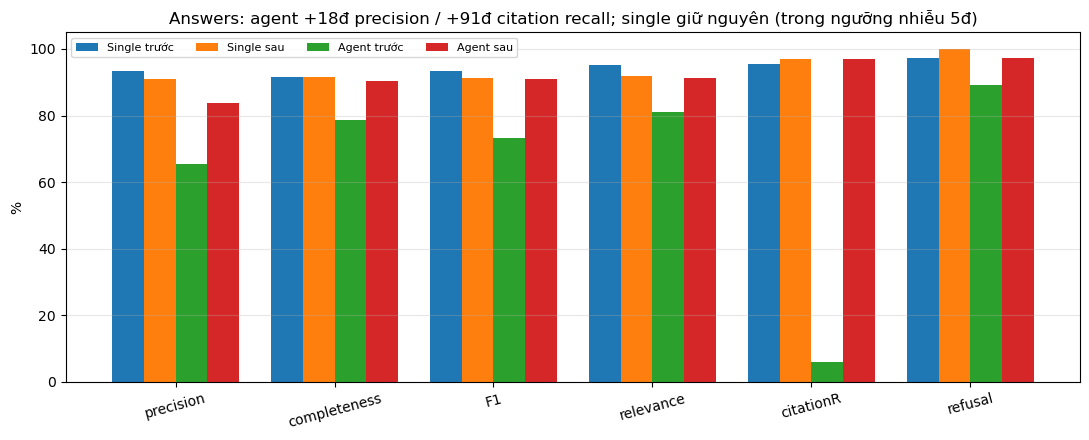

Agent tool call: 0.2 → 3.1/câu | token in: 4616 → 18130 (x3.9)
Agent latency p50/p95: 5.4s/10.3s → 11.4s/23.3s
Single latency p50: 6.2s → 6.5s (+0.3s: rerank +1s, prompt ngắn bù lại)


In [8]:
# Cell 4 — answers before→after: single-shot vs agent
import matplotlib.pyplot as plt
b = load_json_cached(str(ANS_BEFORE)); a = load_json_cached(str(ANS_AFTER))
def summ(d, mode): return next(s for s in d["summaries"] if s["mode"] == mode)
sb, sa = summ(b, "single-shot"), summ(a, "single-shot")
ab, aa = summ(b, "agent"), summ(a, "agent")
labels = ["precision", "completeness", "F1", "relevance", "citationR", "refusal"]
keys = ["answerPrecision", "completeness", "f1", "relevance", "citationRecall", "refusalAccuracy"]
# citation run trước đã chấm lại (parser fix): single 0.955, agent 0.061 — xem METRICS §2.1 chú thích ¹
sb["metrics"]["citationRecall"], ab["metrics"]["citationRecall"] = 0.955, 0.061
sv = [sb["metrics"][k]*100 for k in keys]; sv2 = [sa["metrics"][k]*100 for k in keys]
av = [ab["metrics"][k]*100 for k in keys]; av2 = [aa["metrics"][k]*100 for k in keys]
x = range(len(labels)); w = 0.2
plt.figure(figsize=(11, 4.5))
plt.bar([i-1.5*w for i in x], sv, w, label="Single trước"); plt.bar([i-0.5*w for i in x], sv2, w, label="Single sau")
plt.bar([i+0.5*w for i in x], av, w, label="Agent trước"); plt.bar([i+1.5*w for i in x], av2, w, label="Agent sau")
plt.xticks(list(x), labels, rotation=15); plt.ylabel("%"); plt.ylim(0, 105)
plt.title("Answers: agent +18đ precision / +91đ citation recall; single giữ nguyên (trong ngưỡng nhiễu 5đ)")
plt.legend(fontsize=8, ncol=4); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()
print(f"Agent tool call: {ab.get('meanToolCalls'):.1f} → {aa.get('meanToolCalls'):.1f}/câu | token in: {ab['tokens']['meanInput']:.0f} → {aa['tokens']['meanInput']:.0f} (x3.9)")
print(f"Agent latency p50/p95: {ab['latency']['p50']/1000:.1f}s/{ab['latency']['p95']/1000:.1f}s → {aa['latency']['p50']/1000:.1f}s/{aa['latency']['p95']/1000:.1f}s")
print(f"Single latency p50: {sb['latency']['p50']/1000:.1f}s → {sa['latency']['p50']/1000:.1f}s (+0.3s: rerank +1s, prompt ngắn bù lại)")

## 5. Kết quả này chứng minh điều gì? (kết luận + giới hạn)

**Chứng minh được:**

1. **Bật reranker cho cả 2 mode** — Hit@1 +21.2đ (69.7% → 90.9%), MRR 0.802 → 0.947, Hit@8 giữ 100% nên prompt cắt 20 → 8 chunk (−60% ngữ cảnh) mà completeness single-shot vẫn 91.7%, citation recall lên 97%.
2. **Agent giờ thực sự tra vault** — trước `tool_choice` tự do nên 35/37 câu 0 tool call (precision 65%, citation recall 6%); sau `AGENT_MIN_TOOL_CALLS=1` (lượt đầu `tool_choice: required`) đạt 3.1 tool/câu, precision 83.7% (+18đ), completeness 90.4% (+12đ). Đánh đổi: chậm ~2× (p50 5.4s → 11.4s), token input ×3.9 (gửi lại transcript mỗi lượt) — nên giữ agent là **opt-in**.
3. **Rerank mở đường từ chối câu ngoài phạm vi** bằng ngưỡng điểm (~0.1) — cosine không làm được.

**Chưa chứng minh được / giới hạn:** 37 câu 1 lần chạy (1 câu ≈ 3đ) + judge là LLM → chênh single −2.5đ precision nằm dưới ngưỡng nhiễu 5đ, cần `--repeats 3`; câu hỏi soạn sau khi đọc tài liệu nên dễ hơn câu thật; 8 file ISTQB không có bản local nên bị tính sai làm precision/thứ hạng thấp hơn thực tế; 1 câu agent tụt (`static-cc-01` ΔF1 −0.67) và 1 câu single tụt (`qality-mapping-01` câu 2 nguồn) cần đọc tay.

**Chạy lại:** `npm run eval:rag -- --rerank --candidates 40 --label rerank-check` · `npm run eval:answers -- --yes --label after --baseline latest` (xem `eval/README.md`).

In [9]:
# Cell 5 (tuỳ chọn) — bảng câu đổi hạng + giải phóng RAM
import textwrap
# Đọc comparison.md có sẵn (nhẹ hơn parse results full)
comp = (RAG_RUNS / "2026-10-09T10-00-49-135Z-prod-rerank-v2-comparison.md").read_text(encoding="utf-8")
print(comp[:2200])
print("\n---\nGiải phóng cache nặng nếu cần:")
# load_json_cached.cache_clear()  # bỏ comment dòng này nếu muốn đo RAM sạch
print("Xong. RAM chỉ giữ summaries (~KB), không giữ embeddings/vectors.")

# Rerank vs vector order — bge-reranker-v2-m3, 40 candidates

- MRR: 0.802 → 0.947
- Questions improved / worsened / unchanged: 9 / 1 / 23
- Rerank latency: p50 1061 ms · p95 1635 ms · max 2660 ms (37 calls, 68 passages/call)

| k | Hit@k vector | Hit@k rerank | Δ pts | Precision@k vector | Precision@k rerank | Δ pts | Recall@k rerank |
|---|---|---|---|---|---|---|---|
| 1 | 69.7% | 90.9% | +21.2 | 69.7% | 90.9% | +21.2 | 86.4% |
| 3 | 90.9% | 97.0% | +6.1 | 41.4% | 46.5% | +5.1 | 97.0% |
| 5 | 90.9% | 100.0% | +9.1 | 30.9% | 34.5% | +3.6 | 100.0% |
| 8 | 100.0% | 100.0% | +0.0 | 23.5% | 26.1% | +2.7 | 100.0% |
| 10 | 100.0% | 100.0% | +0.0 | 20.0% | 21.8% | +1.8 | 100.0% |
| 20 | 100.0% | 100.0% | +0.0 | 13.6% | 14.1% | +0.5 | 100.0% |

## First relevant rank changes
| id | vector | rerank |
|----|--------|--------|
| fund-risk-01 | 3 | 1 |
| sdlc-vmodel-01 | 3 | 1 |
| levels-acceptance-01 | 6 | 2 |
| blackbox-ep-01 | 7 | 1 |
| whitebox-01 | 2 | 1 |
| combine-bb-wb-01 | 2 | 1 |
| exp